# 04 · Visualization

**Stage 4 of 8** · ACCESS → WRANGLE → EXPLORE → VISUALIZE → ENGINEER → MODEL → EVALUATE → RECOMMEND

> **Project premise:** if someone has had cancer and was treated, **will it come back?** And for every factor linked to it coming back: **correlation or causation?**
>
> All data here is public: a k-anonymous feature table (every combination of site group, region, sex and diagnosis period is shared by ≥ 3 patients), synthetic patients, and aggregate reports. The raw database and clinical notes stay private.

**Goal of this stage:** turn the EDA findings into charts that answer a question, choosing each chart by the question and the variable types.

**Business question:** How do we show clearly how often, how fast, and for whom cancer comes back?

In [1]:
%matplotlib inline
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
PUBLIC = ROOT / "data" / "public" / "patients_features_public.csv"
SYNTH = ROOT / "data" / "synthetic" / "synthetic_patients.csv"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.axisbelow": True, "figure.dpi": 110})
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
df = pd.read_csv(PUBLIC)

In [2]:
from lifelines import KaplanMeierFitter
at_risk = df[df.eligible_for_relapse == 1].copy(); at_risk["relapse"] = at_risk.relapse.astype(int)

| Question | Variable types | Chart |
|---|---|---|
| Compare relapse across cancer types | category → rate | **Bar chart** |
| How long have patients been followed? | one numeric | **Histogram** |
| Does follow-up differ by outcome? | numeric × category | **Box plot** |
| How fast does it come back? | time → probability | **Line (step) chart**, Kaplan–Meier |
| Relationship of two numerics | numeric × numeric | **Scatter plot** |

### Q1 · Bar chart: relapse rate by cancer type (only groups with ≥ 5 patients)

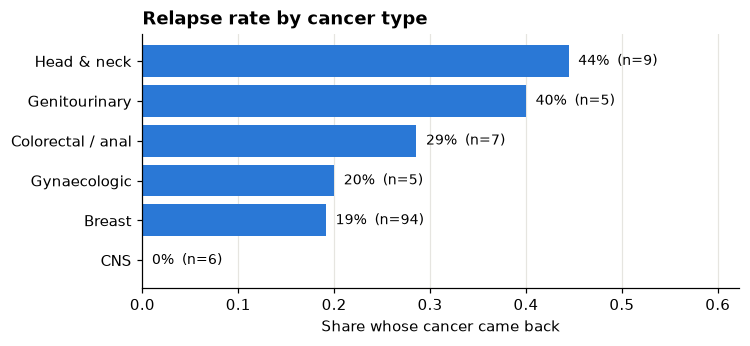

In [3]:
g = at_risk.groupby("site_group").relapse.agg(["size", "mean"])
g = g[g["size"] >= 5].sort_values("mean")
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(g.index, g["mean"], color=BLUE)
for i, (n, r) in enumerate(zip(g["size"], g["mean"])):
    ax.text(r + 0.01, i, f"{r:.0%}  (n={n})", va="center", fontsize=9)
ax.set_xlim(0, max(g["mean"]) * 1.4); ax.set_xlabel("Share whose cancer came back"); ax.grid(axis="y", visible=False)
ax.set_title("Relapse rate by cancer type", loc="left", weight="bold"); plt.show()

### Q2 · Histogram: how long have at-risk patients been followed?

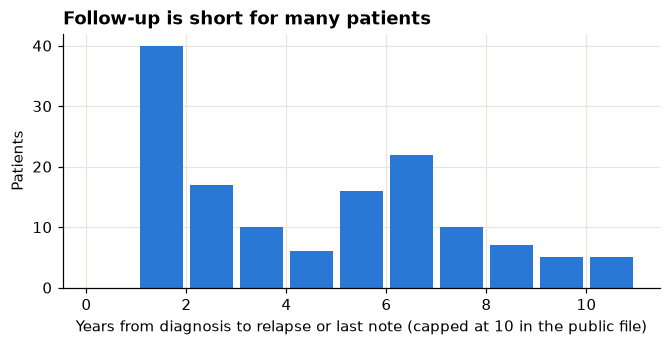

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(at_risk.rfs_years, bins=range(0, 12), color=BLUE, rwidth=0.85)
ax.set_xlabel("Years from diagnosis to relapse or last note (capped at 10 in the public file)"); ax.set_ylabel("Patients")
ax.set_title("Follow-up is short for many patients", loc="left", weight="bold"); plt.show()

### Q3 · Box plot: follow-up time for patients with and without relapse

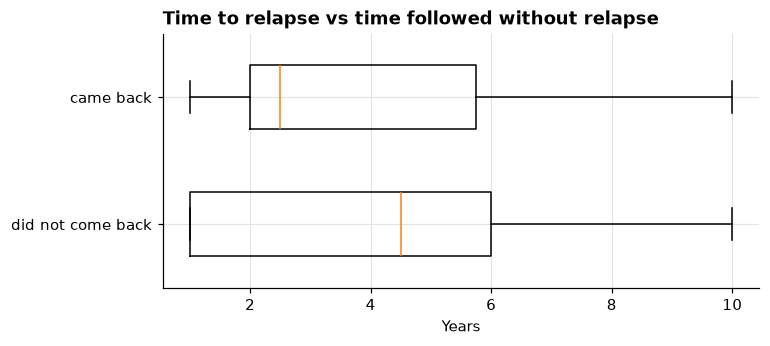

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
data = [at_risk.loc[at_risk.relapse == k, "rfs_years"] for k in (0, 1)]
ax.boxplot(data, vert=False, tick_labels=["did not come back", "came back"], widths=0.5)
ax.set_xlabel("Years"); ax.set_title("Time to relapse vs time followed without relapse", loc="left", weight="bold"); plt.show()

### Q4 · Line chart over time: how fast does cancer come back? (Kaplan–Meier)

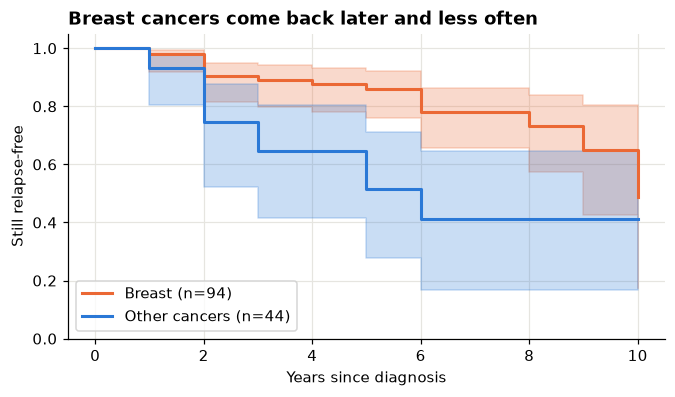

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
is_breast = at_risk.site_group == "Breast"
for mask, lab, col in ((is_breast, "Breast", ORANGE), (~is_breast, "Other cancers", BLUE)):
    KaplanMeierFitter().fit(at_risk.rfs_years[mask], at_risk.relapse[mask], label=f"{lab} (n={mask.sum()})") \
        .plot_survival_function(ax=ax, color=col, lw=2)
ax.set_ylim(0, 1.05); ax.set_xlabel("Years since diagnosis"); ax.set_ylabel("Still relapse-free")
ax.set_title("Breast cancers come back later and less often", loc="left", weight="bold"); plt.show()

### Q5 · Scatter plot: years since diagnosis vs number of clinic visits

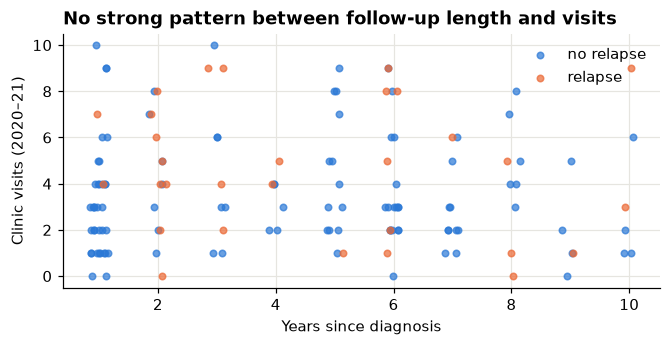

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
for k, col, lab in ((0, BLUE, "no relapse"), (1, ORANGE, "relapse")):
    s = at_risk[at_risk.relapse == k]
    ax.scatter(s.years_since_dx + np.random.uniform(-.15, .15, len(s)), s.n_visits, s=18, color=col, alpha=.7, label=lab)
ax.set_xlabel("Years since diagnosis"); ax.set_ylabel("Clinic visits (2020–21)"); ax.legend(frameon=False)
ax.set_title("No strong pattern between follow-up length and visits", loc="left", weight="bold"); plt.show()

### Q6 · The chart that carries the main finding (from `reports/figures`)

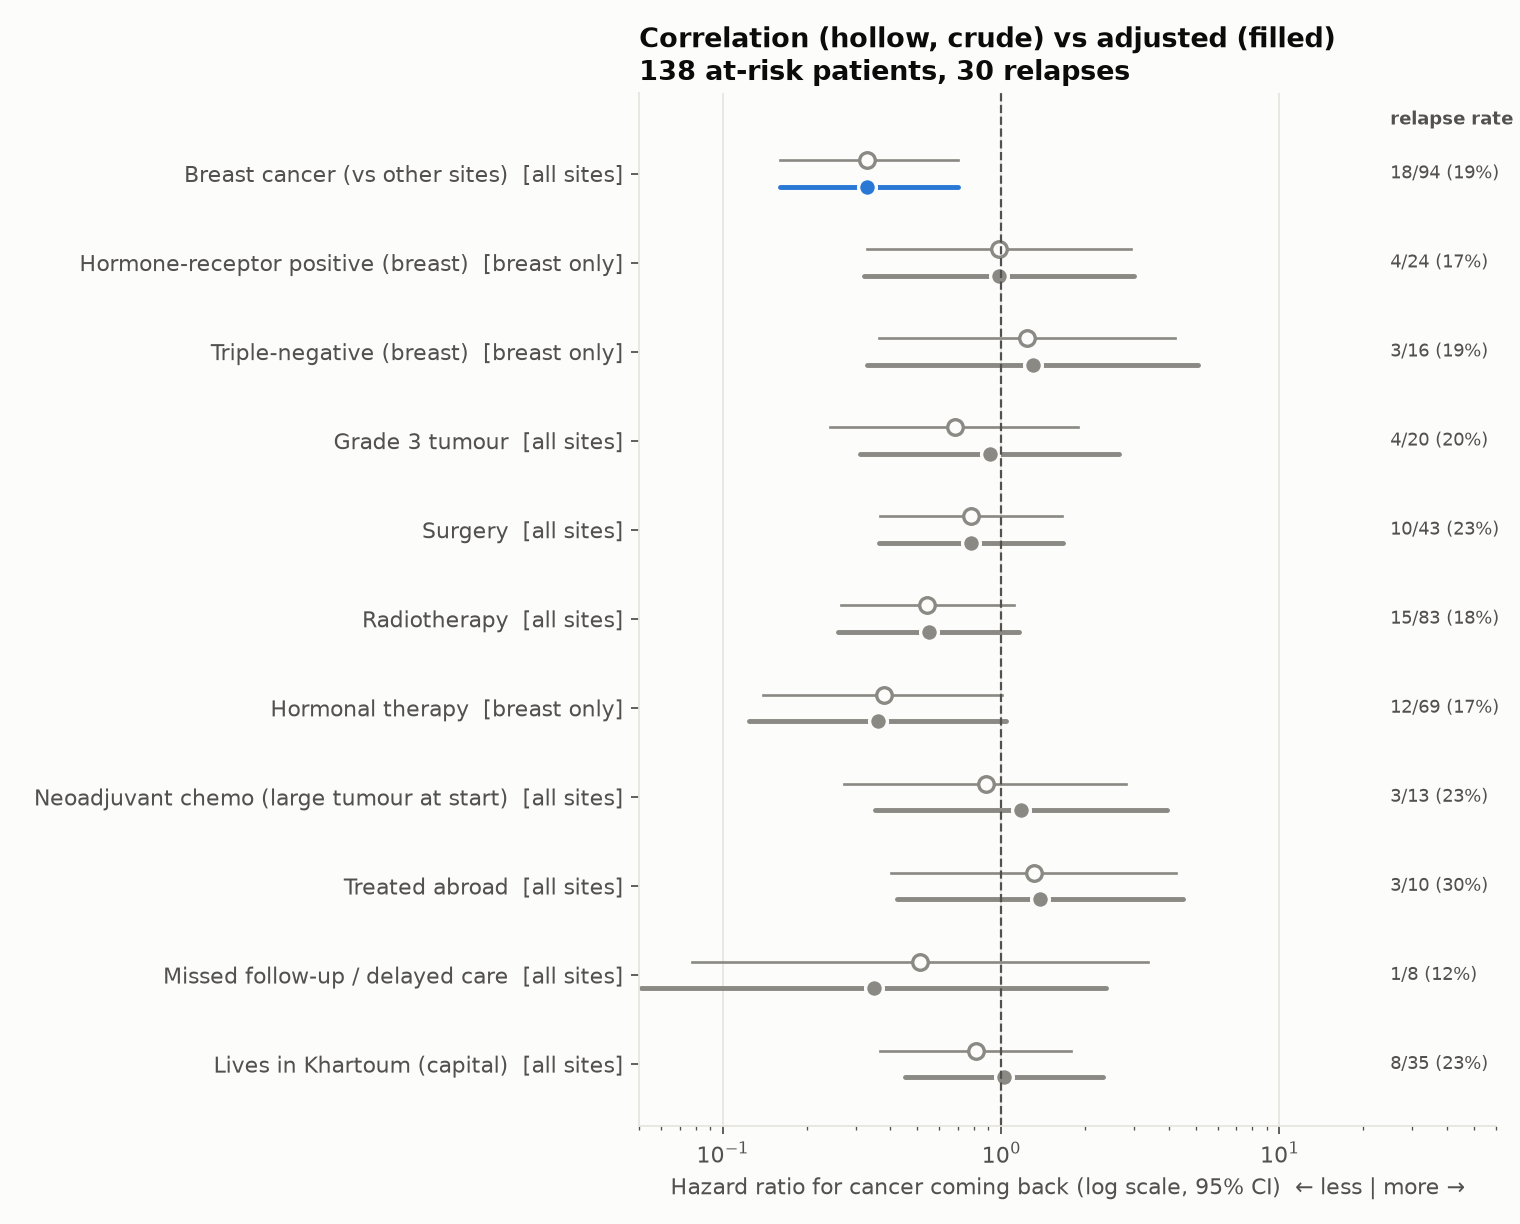

In [8]:
from IPython.display import Image
Image(str(ROOT / "reports" / "figures" / "08_relapse_forest_plot.png"), width=760)

### Q7 · Chart → observation → meaning
- **Observation:** hollow (crude) and filled (adjusted) markers for hormonal therapy and radiotherapy sit left of 1,
  but their lines cross 1. Only "breast vs other" stays clearly left of 1.
- **Meaning:** the only factor this data clearly links to cancer coming back is **cancer type**. Treatment
  effects point the right way, but the data is too small to prove them.

## So what?

A Kaplan–Meier curve answers the premise more honestly than any bar chart, because it respects that patients were
followed for different lengths of time. The forest plot is the bridge from correlation (crude) to the
causation question (adjusted).